# **Mini-Proyecto 2 Bioinformática: Análisis de datos (DM y ML)**

**Dataset:** Yeast (Protein Localization Sites), UCI Machine Learning Repository

https://archive.ics.uci.edu/dataset/110/yeast

## **1- Dataset y objetivo**

El dataset reúne 1484 proteínas de la levadura *Saccharomyces cerevisiae*. Para cada proteína hay 8 puntajes que salen del análisis de su secuencia de aminoácidos (señales de direccionamiento, regiones de membrana, composición del extremo N-terminal, etc.) y el sitio de la célula donde se ubica la proteína.

Es el mismo tipo de problema que vimos en clase con el dataset de *E. coli*, pero en una célula eucariota, con más compartimentos y más clases.

**Objetivo:** predecir el sitio de localización subcelular de una proteína de levadura (citosol, núcleo, mitocondria, membrana, etc.) a partir de los 8 puntajes calculados sobre su secuencia, usando métodos de data mining (PCA) y de machine learning (Random Forest, árboles de decisión, SVM y redes neuronales).

Como referencia, en el trabajo original de Horton y Nakai (1996) se llegó a una precisión del 55% con un modelo probabilístico.

## **2- Apertura del conjunto de datos**

**Importación de bibliotecas**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
column_names = ['protein', 'mcg', 'gvh', 'alm', 'mit', 'erl', 'pox', 'vac', 'nuc', 'site'] # Lista de nombres

In [3]:
df = pd.read_csv("yeast.data", header=None, sep=r'\s+', names=column_names) # leer el dataframe

In [4]:
df # imprimir el dataframe en pantalla

,protein,mcg,gvh,alm,mit,erl,pox,vac,nuc,site
0,ADT1_YEAST,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,ADT2_YEAST,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,ADT3_YEAST,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,AAR2_YEAST,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,AATM_YEAST,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT
...,...,...,...,...,...,...,...,...,...,...
1479,YUR1_YEAST,0.81,0.62,0.43,0.17,0.5,0.0,0.53,0.22,ME2
1480,ZIP1_YEAST,0.47,0.43,0.61,0.40,0.5,0.0,0.48,0.47,NUC
1481,ZNRP_YEAST,0.67,0.57,0.36,0.19,0.5,0.0,0.56,0.22,ME2
1482,ZUO1_YEAST,0.43,0.40,0.60,0.16,0.5,0.0,0.53,0.39,NUC


**¿Cuántas columnas hay? Describir cada una de ellas.**

In [5]:
print(f'Número de columnas: {df.shape[1]}')
print(df.columns.tolist())

Número de columnas: 10
['protein', 'mcg', 'gvh', 'alm', 'mit', 'erl', 'pox', 'vac', 'nuc', 'site']


Hay **10 columnas**:

| Columna | Descripción |
|---|---|
| **protein** | Nombre de la secuencia (código de acceso en la base de datos SWISS-PROT). Es un identificador de la proteína. |
| **mcg** | Puntaje del método de McGeoch para reconocer secuencias señal. |
| **gvh** | Puntaje del método de von Heijne para reconocer secuencias señal. |
| **alm** | Puntaje del programa ALOM, que predice regiones que atraviesan la membrana. |
| **mit** | Puntaje del análisis discriminante de la composición de aminoácidos de la región N-terminal (20 residuos), que separa proteínas mitocondriales de no mitocondriales. |
| **erl** | Presencia de la secuencia "HDEL", una señal de retención en el lumen del retículo endoplasmático. Es binaria. |
| **pox** | Señal de direccionamiento al peroxisoma en el extremo C-terminal. |
| **vac** | Puntaje del análisis discriminante de la composición de aminoácidos de proteínas vacuolares y extracelulares. |
| **nuc** | Puntaje del análisis discriminante de señales de localización nuclear. |
| **site** | Sitio de localización de la proteína dentro de la célula. Es la variable objetivo. |

**¿Cuántos datos tiene el conjunto de datos?**

In [6]:
print(f'Número de filas (datos): {df.shape[0]}')

Número de filas (datos): 1484


El conjunto tiene **1484 datos** (una fila por proteína).

**¿Cuál es la variable objetivo, y cuáles y cuántas son las clases que toma la misma?**

In [7]:
print(df['site'].unique())
print(f"Número de clases: {df['site'].nunique()}")

['MIT' 'NUC' 'CYT' 'ME1' 'EXC' 'ME2' 'ME3' 'VAC' 'POX' 'ERL']
Número de clases: 10


La variable objetivo es **site** (sitio de localización). Toma **10 clases**:

- **CYT**: citosólica o del citoesqueleto
- **NUC**: nuclear
- **MIT**: mitocondrial
- **ME3**: proteína de membrana sin señal N-terminal
- **ME2**: proteína de membrana con señal no escindida
- **ME1**: proteína de membrana con señal escindida
- **EXC**: extracelular
- **VAC**: vacuolar
- **POX**: peroxisomal
- **ERL**: lumen del retículo endoplasmático

**¿Cuántos features numéricos y categóricos tiene?**

In [8]:
df.dtypes

,0
protein,object
mcg,float64
gvh,float64
alm,float64
mit,float64
erl,float64
pox,float64
vac,float64
nuc,float64
site,object


Sin contar la variable objetivo, hay **8 features numéricos** (mcg, gvh, alm, mit, erl, pox, vac, nuc) y **1 feature categórico** (protein, que es texto).

Aunque erl y pox son numéricos, toman muy pocos valores distintos (se ve más abajo), así que en la práctica se comportan casi como variables discretas.

**¿De las features numéricas, cuáles son sus mínimos y máximos?**

In [9]:
df.describe()

,mcg,gvh,alm,mit,erl,pox,vac,nuc
count,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000
mean,0.500121,0.499933,0.500034,0.261186,0.504717,0.007500,0.499885,0.276199
std,0.137299,0.123924,0.086670,0.137098,0.048351,0.075683,0.057797,0.106491
min,0.110000,0.130000,0.210000,0.000000,0.500000,0.000000,0.000000,0.000000
25%,0.410000,0.420000,0.460000,0.170000,0.500000,0.000000,0.480000,0.220000
50%,0.490000,0.490000,0.510000,0.220000,0.500000,0.000000,0.510000,0.220000
75%,0.580000,0.570000,0.550000,0.320000,0.500000,0.000000,0.530000,0.300000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.830000,0.730000,1.000000


In [10]:
# Mínimos y máximos de cada feature numérico
min_max = df.describe().loc[['min', 'max']].T
print(min_max)

      min   max
mcg  0.11  1.00
gvh  0.13  1.00
alm  0.21  1.00
mit  0.00  1.00
erl  0.50  1.00
pox  0.00  0.83
vac  0.00  0.73
nuc  0.00  1.00


In [11]:
# Valores únicos de erl y pox
print('erl:', df['erl'].unique())
print('pox:', df['pox'].unique())

erl: [0.5 1. ]
pox: [0.   0.5  0.83]


| Feature | Mínimo | Máximo |
|---|---|---|
| mcg | 0.11 | 1.00 |
| gvh | 0.13 | 1.00 |
| alm | 0.21 | 1.00 |
| mit | 0.00 | 1.00 |
| erl | 0.50 | 1.00 |
| pox | 0.00 | 0.83 |
| vac | 0.00 | 0.73 |
| nuc | 0.00 | 1.00 |

erl solo toma dos valores (0.5 y 1.0) y pox tres (0.0, 0.5 y 0.83).

**¿De las features categóricas, cuántos valores únicos tienen?**

In [12]:
print(f"Valores únicos de protein: {df['protein'].nunique()}")
print(f"Valores únicos de site: {df['site'].nunique()}")

Valores únicos de protein: 1462
Valores únicos de site: 10


La única feature categórica, **protein**, tiene **1462 valores únicos**. Como hay 1484 filas, quiere decir que algunos nombres de proteína se repiten. La variable objetivo **site** tiene 10 valores únicos.

In [13]:
# Revisar las filas repetidas
print(f'Filas completamente duplicadas: {df.duplicated().sum()}')
print(f"Nombres de proteína repetidos: {df['protein'].duplicated().sum()}")

Filas completamente duplicadas: 22
Nombres de proteína repetidos: 22


Las 22 repeticiones son filas idénticas (mismo nombre y mismos valores). Se decidió dejarlas para trabajar con el dataset tal como lo publica el repositorio, pero hay que tenerlo en cuenta porque son pocas (1.5% de los datos).

## **3- Preparación de los datos**

**¿Hay valores faltantes? ¿Cuántos?**

In [14]:
df.isnull().sum()

,0
protein,0
mcg,0
gvh,0
alm,0
mit,0
erl,0
pox,0
vac,0
nuc,0
site,0


In [15]:
print(f'Total de valores faltantes: {df.isnull().sum().sum()}')

Total de valores faltantes: 0


No hay valores faltantes (0 en todas las columnas), lo cual coincide con lo que dice el archivo `yeast.names`.

**Si decidiera eliminar las filas con valores faltantes, ¿cuántas eliminaría?**

In [16]:
filas_con_faltantes = df.isnull().any(axis=1).sum()
print(f'Filas que se eliminarían: {filas_con_faltantes}')

Filas que se eliminarían: 0


No se eliminaría ninguna fila, porque no hay datos faltantes.

**Pasar las variables categóricas a números**

In [17]:
from sklearn.preprocessing import LabelEncoder

datos_limpios = df.copy()

# Codificar la columna protein
le_protein = LabelEncoder()
datos_limpios['protein'] = le_protein.fit_transform(datos_limpios['protein'])

# Codificar las clases (columna site)
label_encoder = LabelEncoder()
datos_limpios['site'] = label_encoder.fit_transform(datos_limpios['site'])

# Imprimir las correspondencias entre etiquetas originales y valores numéricos
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Correspondencia entre etiquetas originales y valores numéricos:")
print(label_mapping)

Correspondencia entre etiquetas originales y valores numéricos:
{'CYT': 0, 'ERL': 1, 'EXC': 2, 'ME1': 3, 'ME2': 4, 'ME3': 5, 'MIT': 6, 'NUC': 7, 'POX': 8, 'VAC': 9}


In [18]:
datos_limpios

,protein,mcg,gvh,alm,mit,erl,pox,vac,nuc,site
0,32,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,6
1,33,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,6
2,34,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,6
3,2,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,7
4,4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,6
...,...,...,...,...,...,...,...,...,...,...
1479,1458,0.81,0.62,0.43,0.17,0.5,0.0,0.53,0.22,4
1480,1459,0.47,0.43,0.61,0.40,0.5,0.0,0.48,0.47,7
1481,1460,0.67,0.57,0.36,0.19,0.5,0.0,0.56,0.22,4
1482,1461,0.43,0.40,0.60,0.16,0.5,0.0,0.53,0.39,7


La columna protein queda codificada, pero no se va a usar como feature en los modelos: es solo el nombre de la proteína y no aporta información biológica para predecir dónde se ubica.

**Guardar el DataFrame limpio en un archivo de texto**

In [19]:
# Guarda el DataFrame en un archivo .txt
datos_limpios.to_csv('datos_limpios.txt', index=False)

**¿Las clases están balanceadas? ¿Cuántos datos tiene cada una de ellas?**

In [20]:
# Obtener las frecuencias de clases
clases_total = df['site'].value_counts()

print(clases_total)

# Calcular el total de frecuencias
total_frecuencias = clases_total.sum()

print(f'Total {total_frecuencias}')

site
CYT    463
NUC    429
MIT    244
ME3    163
ME2     51
ME1     44
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64
Total 1484


In [21]:
# Porcentaje de cada clase
print((clases_total / total_frecuencias * 100).round(2))

site
CYT    31.20
NUC    28.91
MIT    16.44
ME3    10.98
ME2     3.44
ME1     2.96
EXC     2.36
VAC     2.02
POX     1.35
ERL     0.34
Name: count, dtype: float64


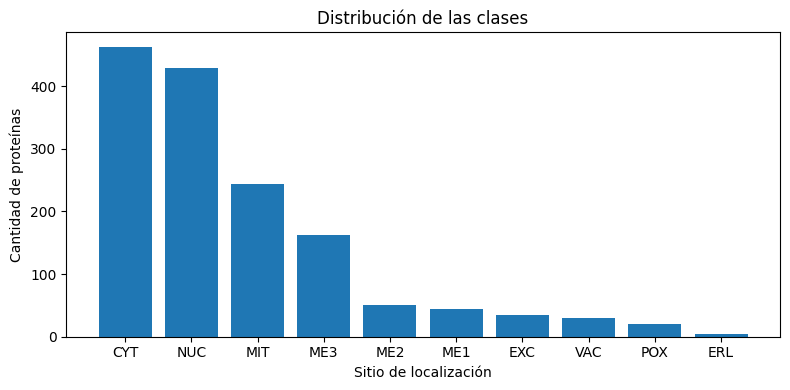

In [22]:
plt.figure(figsize=(8, 4))
plt.bar(clases_total.index, clases_total.values)
plt.xlabel('Sitio de localización')
plt.ylabel('Cantidad de proteínas')
plt.title('Distribución de las clases')
plt.tight_layout()
plt.show()

Las clases **no están balanceadas**. Cantidad de datos por clase:

| Clase | Datos | % |
|---|---|---|
| CYT | 463 | 31.20 |
| NUC | 429 | 28.91 |
| MIT | 244 | 16.44 |
| ME3 | 163 | 10.98 |
| ME2 | 51 | 3.44 |
| ME1 | 44 | 2.96 |
| EXC | 35 | 2.36 |
| VAC | 30 | 2.02 |
| POX | 20 | 1.35 |
| ERL | 5 | 0.34 |

Entre CYT y NUC se juntan más del 60% de los datos, mientras que ERL tiene solo 5 proteínas. Esto va a hacer que a los modelos les cueste mucho reconocer las clases chicas.

Dato a tener en cuenta: el archivo `yeast.names` dice que EXC tiene 37 datos, pero en el archivo de datos hay 35. El total igual da 1484.

## **4- Visualización y reducción de la dimensionalidad de los datos**

**¿Cuántas dimensiones habría en el caso que uno quisiera utilizar directamente a todos los features para graficar?**

Habría **8 dimensiones**, una por cada feature numérico (mcg, gvh, alm, mit, erl, pox, vac, nuc). No se puede graficar directamente, por eso se usa PCA para bajar a 2 dimensiones.

**¿Las features están todas medidas con las mismas unidades?**

No. No son mediciones con una unidad física, sino puntajes que salen de métodos distintos (dos métodos de secuencia señal, un predictor de regiones de membrana, varios análisis discriminantes y señales binarias o discretas como erl y pox). Están todos llevados a valores entre 0 y 1, pero cada uno tiene su propio rango (por ejemplo, alm va de 0.21 a 1, erl de 0.5 a 1 y vac de 0 a 0.73) y su propia forma de calcularse.

**Separar los datos de las clases**

In [23]:
# separar las características X y las etiquetas y
X = datos_limpios.iloc[:, 1:9].values # columnas 2 a 9 (mcg a nuc), sin protein
y = datos_limpios.iloc[:, 9].values   # última columna, con las clases ya codificadas

In [24]:
X

array([[0.58, 0.61, 0.47, ..., 0.  , 0.48, 0.22],
       [0.43, 0.67, 0.48, ..., 0.  , 0.53, 0.22],
       [0.64, 0.62, 0.49, ..., 0.  , 0.53, 0.22],
       ...,
       [0.67, 0.57, 0.36, ..., 0.  , 0.56, 0.22],
       [0.43, 0.4 , 0.6 , ..., 0.  , 0.53, 0.39],
       [0.65, 0.54, 0.54, ..., 0.  , 0.53, 0.22]])

In [25]:
y

array([6, 6, 6, ..., 4, 7, 0])

**Normalizar los datos usando MinMaxScaler()**

In [26]:
from sklearn.preprocessing import MinMaxScaler

# Crear un objeto MinMaxScaler
scaler = MinMaxScaler()

# Normalizar los datos
yeast_normalized = scaler.fit_transform(X)

# Convertirlo a un DataFrame para mejor visualización
feature_names = column_names[1:9]
yeast_normalized_df = pd.DataFrame(yeast_normalized, columns=feature_names)
print(yeast_normalized_df)

           mcg       gvh       alm   mit  erl  pox       vac   nuc
0     0.528090  0.551724  0.329114  0.13  0.0  0.0  0.657534  0.22
1     0.359551  0.620690  0.341772  0.27  0.0  0.0  0.726027  0.22
2     0.595506  0.563218  0.354430  0.15  0.0  0.0  0.726027  0.22
3     0.528090  0.356322  0.455696  0.13  0.0  0.0  0.739726  0.22
4     0.348315  0.356322  0.341772  0.54  0.0  0.0  0.657534  0.22
...        ...       ...       ...   ...  ...  ...       ...   ...
1479  0.786517  0.563218  0.278481  0.17  0.0  0.0  0.726027  0.22
1480  0.404494  0.344828  0.506329  0.40  0.0  0.0  0.657534  0.47
1481  0.629213  0.505747  0.189873  0.19  0.0  0.0  0.767123  0.22
1482  0.359551  0.310345  0.493671  0.16  0.0  0.0  0.726027  0.39
1483  0.606742  0.471264  0.417722  0.13  0.0  0.0  0.726027  0.22

[1484 rows x 8 columns]


In [27]:
# Ver el resumen estadístico con los datos normalizados
summary = yeast_normalized_df.describe()
print(summary)

               mcg          gvh          alm          mit          erl  \
count  1484.000000  1484.000000  1484.000000  1484.000000  1484.000000   
mean      0.438339     0.425210     0.367131     0.261186     0.009434   
std       0.154269     0.142442     0.109709     0.137098     0.096702   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.337079     0.333333     0.316456     0.170000     0.000000   
50%       0.426966     0.413793     0.379747     0.220000     0.000000   
75%       0.528090     0.505747     0.430380     0.320000     0.000000   
max       1.000000     1.000000     1.000000     1.000000     1.000000   

               pox          vac          nuc  
count  1484.000000  1484.000000  1484.000000  
mean      0.009036     0.684775     0.276199  
std       0.091184     0.079173     0.106491  
min       0.000000     0.000000     0.000000  
25%       0.000000     0.657534     0.220000  
50%       0.000000     0.698630     0.220000  
75% 

**¿Por qué es importante normalizar los datos antes de aplicar PCA?**

Porque PCA busca las direcciones donde los datos tienen más varianza. Si una variable tiene un rango más grande que otra, su varianza también es más grande solo por la escala, y termina "tirando" de los componentes principales aunque no sea más informativa. Al normalizar, todas las variables quedan entre 0 y 1 y compiten en igualdad de condiciones, así PCA refleja la estructura real de los datos y no las diferencias de escala.

**Aplicar PCA para poder visualizar los datos en una gráfica 2D**

In [28]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(yeast_normalized)

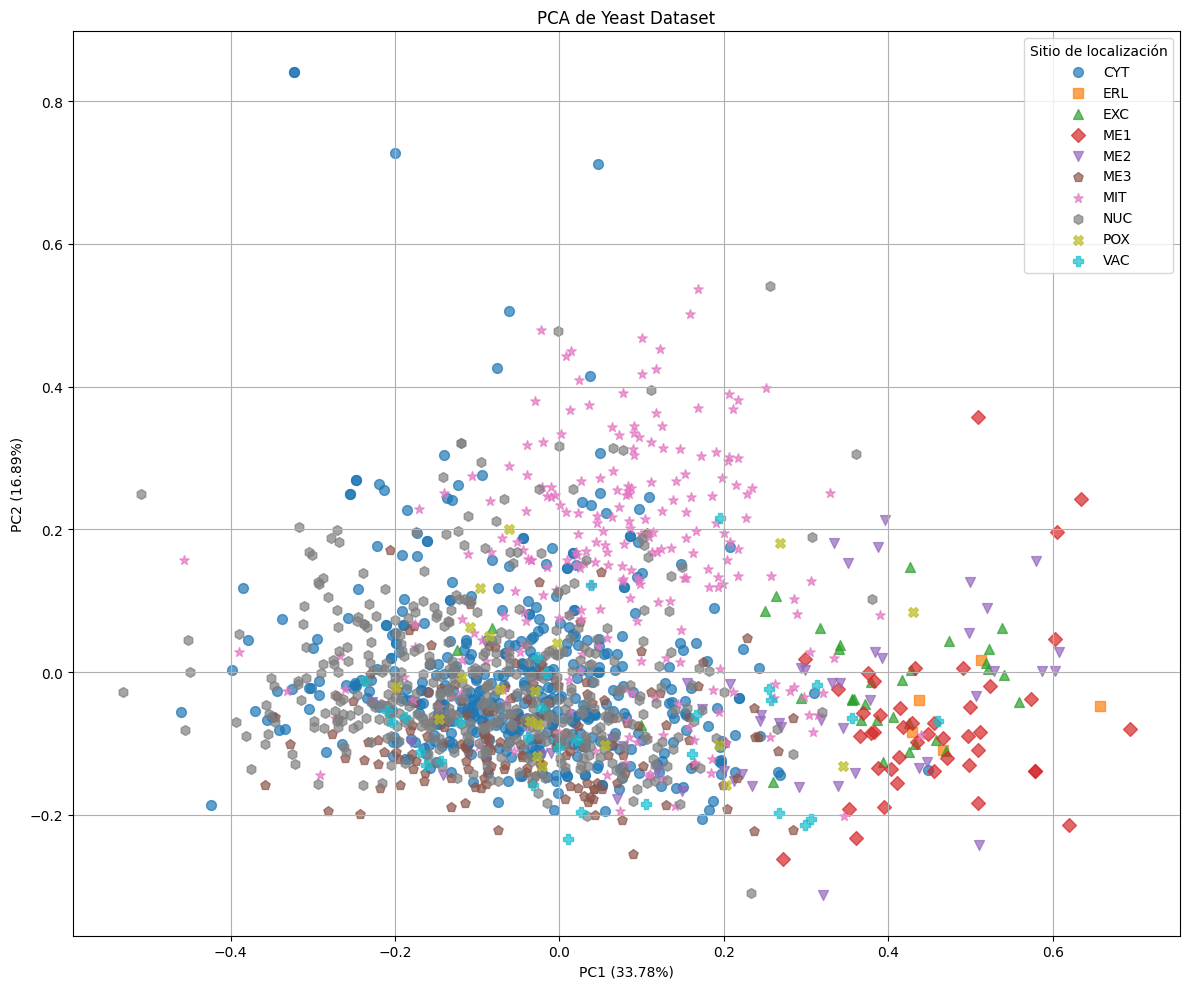

In [29]:
# Etiquetas originales (texto) para la leyenda
sitios = df['site'].values

# DataFrame con los resultados del PCA
pca_data = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
pca_data['site'] = sitios

# Colores y marcadores
cmap = plt.get_cmap('tab10')
markers = ['o', 's', '^', 'D', 'v', 'p', '*', 'h', 'X', 'P']

plt.figure(figsize=(12, 10))

for i, (sitio, grupo) in enumerate(pca_data.groupby('site')):
    plt.scatter(grupo['PC1'], grupo['PC2'],
                color=cmap(i % 10), marker=markers[i % len(markers)],
                label=sitio, alpha=0.7, s=50)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA de Yeast Dataset')
plt.legend(title='Sitio de localización', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

**Verificar la cantidad de varianza que están explicando los primeros componentes principales (PC1 + PC2)**

In [30]:
# Crear un DataFrame con los resultados del PCA
pca_df = pd.DataFrame(data = {
    'standard_deviation': np.sqrt(pca.explained_variance_),
    'proportion_of_variance': pca.explained_variance_ratio_,
    'cumulative_proportion': np.cumsum(pca.explained_variance_ratio_)
})

# Añadir una columna para los componentes principales
pca_df.index = [f'PC{i}' for i in range(1, len(pca_df) + 1)]
pca_df.index.name = 'component'

print("Resumen de PCA:")
print(pca_df)
print("\n")
print(f'Varianza explicada por PC1 + PC2: {np.sum(pca.explained_variance_ratio_[:2]):.2%}')

Resumen de PCA:
           standard_deviation  proportion_of_variance  cumulative_proportion
component                                                                   
PC1                  0.192942                0.337824               0.337824
PC2                  0.136428                0.168906               0.506730
PC3                  0.110031                0.109867               0.616597
PC4                  0.103028                0.096328               0.712925
PC5                  0.096254                0.084078               0.797002
PC6                  0.091830                0.076525               0.873528
PC7                  0.090998                0.075145               0.948673
PC8                  0.075206                0.051327               1.000000


Varianza explicada por PC1 + PC2: 50.67%


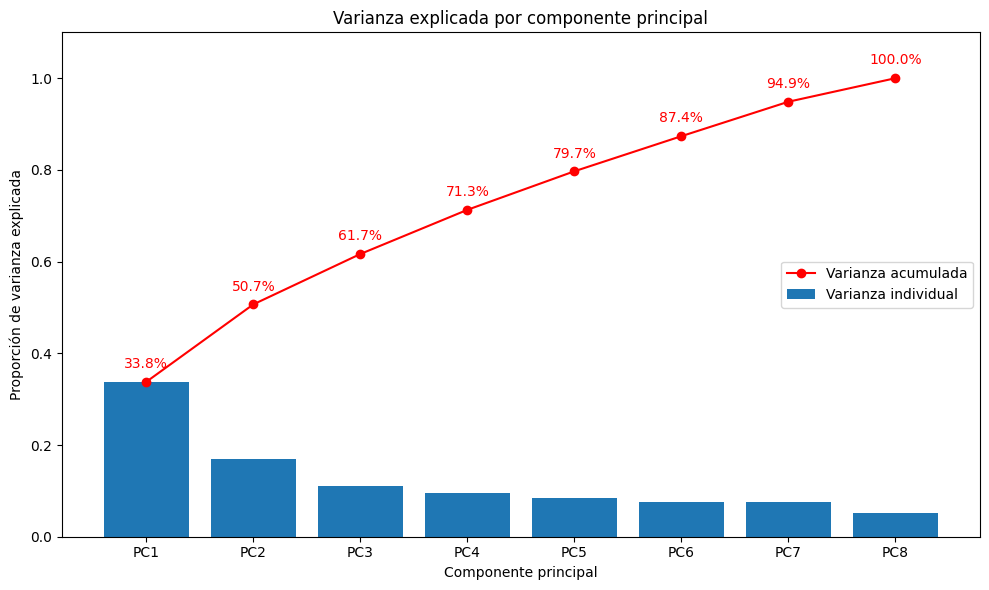

In [31]:
var = pca.explained_variance_ratio_
acum = np.cumsum(var)
pcs = np.arange(1, len(var) + 1)

plt.figure(figsize=(10, 6))
plt.bar(pcs, var, label='Varianza individual')
plt.plot(pcs, acum, marker='o', color='red', label='Varianza acumulada')

# Etiquetar el % acumulado sobre cada punto
for pc, a in zip(pcs, acum):
    plt.text(pc, a + 0.03, f'{a:.1%}', ha='center', color='red')

plt.xticks(pcs, [f'PC{i}' for i in pcs])
plt.ylim(0, 1.1)
plt.xlabel('Componente principal')
plt.ylabel('Proporción de varianza explicada')
plt.title('Varianza explicada por componente principal')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

PC1 explica el 33.78% de la varianza y PC2 el 16.89%, así que **PC1 + PC2 explican el 50.67%**. Es bastante menos que en Iris (>95%) o en los ncRNAs (>87%). La varianza está repartida entre muchos componentes (hacen falta 6 para pasar el 85%), por eso en el gráfico 2D las clases aparecen muy superpuestas, sobre todo CYT y NUC. Solo MIT se separa un poco hacia arriba en PC2.

**Obtener los vectores de carga**

In [32]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(loadings, columns=[f'PC{i}' for i in range(1, len(loadings[0]) + 1)],
                           index=feature_names)

print("Vectores de carga (Loadings):")
print(loadings_df)
print("\n")

Vectores de carga (Loadings):
          PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
mcg  0.713230 -0.077438  0.304931  0.374621 -0.154091 -0.461622 -0.110876   
gvh  0.631803 -0.146137 -0.161073 -0.155768  0.059804  0.706749  0.160144   
alm -0.179167  0.292611  0.621252  0.490556 -0.029959  0.441428  0.106890   
mit  0.216219  0.926713 -0.272067 -0.078848  0.041301 -0.089042  0.010083   
erl  0.044096 -0.037322  0.016271  0.183649  0.973374 -0.091913  0.039599   
pox  0.001887 -0.007505  0.078755 -0.080461 -0.051746 -0.214945  0.965690   
vac  0.041119 -0.145912 -0.176329  0.021470  0.045656 -0.151302  0.059423   
nuc -0.098173 -0.074094 -0.619306  0.740184 -0.133628  0.084155  0.113476   

          PC8  
mcg -0.053387  
gvh  0.023315  
alm  0.220222  
mit  0.066930  
erl -0.072091  
pox -0.076341  
vac  0.957579  
nuc -0.125083  




In [33]:
# Feature con mayor carga (en valor absoluto) para PC1 y PC2
print(f"Feature más relevante para PC1: {loadings_df['PC1'].abs().idxmax()} ({loadings_df['PC1'].abs().max():.4f})")
print(f"Feature más relevante para PC2: {loadings_df['PC2'].abs().idxmax()} ({loadings_df['PC2'].abs().max():.4f})")

Feature más relevante para PC1: mcg (0.7132)
Feature más relevante para PC2: mit (0.9267)


**En base a los vectores de carga, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

- **PC1:** la feature más relevante es **mcg** (carga 0.713), seguida muy de cerca por **gvh** (0.632). Las dos son métodos de reconocimiento de secuencias señal, así que PC1 resume básicamente "cuánta señal de secreción tiene la proteína".
- **PC2:** la feature más relevante es **mit** (carga 0.927), muy por encima del resto. PC2 representa la composición de la región N-terminal típica de las proteínas mitocondriales, y por eso en el gráfico las MIT se corren hacia valores altos de PC2.

**Hacer un biplot**

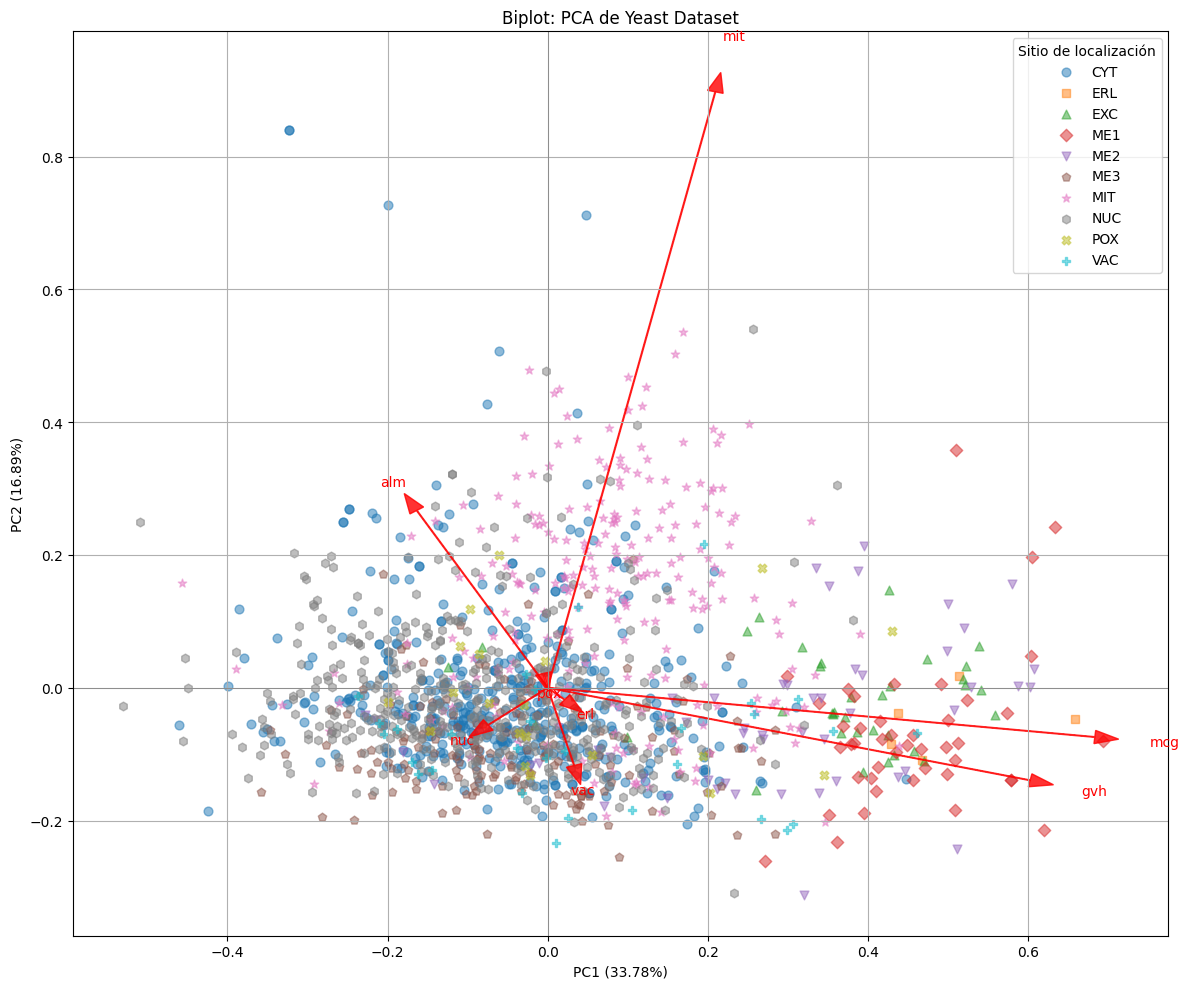

In [34]:
plt.figure(figsize=(12, 10))

# Puntos
for i, (sitio, grupo) in enumerate(pca_data.groupby('site')):
    plt.scatter(grupo['PC1'], grupo['PC2'],
                color=cmap(i % 10), marker=markers[i % len(markers)],
                label=sitio, alpha=0.5, s=40)

# Flechas de las 8 variables
escala = 1     # factor visual para que las flechas se vean junto a los puntos
for j in range(len(feature_names)):
    lx, ly = loadings[j, 0], loadings[j, 1]
    plt.arrow(0, 0, lx * escala, ly * escala, color='r', alpha=0.8,
              head_width=0.02, length_includes_head=True)
    plt.text(lx * escala * 1.08, ly * escala * 1.06, feature_names[j],
             color='r', ha='center', va='center')

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('Biplot: PCA de Yeast Dataset')
plt.legend(title='Sitio de localización', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

**En base al biplot, ¿cuál es la feature más relevante para PC1? ¿Y para PC2?**

En el biplot se confirma lo mismo que con los vectores de carga:

- Para **PC1**, la flecha más larga en la dirección horizontal es la de **mcg**, con **gvh** casi pegada. Las dos apuntan hacia la derecha, hacia donde se ubican las proteínas de membrana con señal (ME1, ME2) y las extracelulares (EXC).
- Para **PC2**, la flecha de **mit** es la más larga y apunta casi vertical hacia arriba, justo donde se concentran las proteínas MIT.
- erl y pox tienen flechas casi nulas, lo que tiene sentido porque casi no varían (erl vale 0.5 en 1470 de las 1484 proteínas).

## **5- Machine learning**

### **Random forest**

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

**Verificar que en X sigan estando las features y en y las etiquetas (clases)**

In [36]:
print('Features (X):')
print(X)
print(f'Dimensiones de X: {X.shape}')

Features (X):
[[0.58 0.61 0.47 ... 0.   0.48 0.22]
 [0.43 0.67 0.48 ... 0.   0.53 0.22]
 [0.64 0.62 0.49 ... 0.   0.53 0.22]
 ...
 [0.67 0.57 0.36 ... 0.   0.56 0.22]
 [0.43 0.4  0.6  ... 0.   0.53 0.39]
 [0.65 0.54 0.54 ... 0.   0.53 0.22]]
Dimensiones de X: (1484, 8)


In [37]:
print('Etiquetas (y):')
print(y)
print(f'Dimensiones de y: {y.shape}')
print(f'Clases: {np.unique(y)}')

Etiquetas (y):
[6 6 6 ... 4 7 0]
Dimensiones de y: (1484,)
Clases: [0 1 2 3 4 5 6 7 8 9]


**Entrenar un modelo Random Forest habilitando oob_score=True**

In [38]:
# Definir y entrenar el modelo Random Forest con OOB (Out-Of-Bag)
rf_model = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)
rf_model.fit(X, y)

RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)

In [39]:
# Imprimir un resumen del modelo
print("Resumen del modelo Random Forest:")
print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {label_encoder.inverse_transform(rf_model.classes_)}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.6307
Número de características: 8
Clases: ['CYT' 'ERL' 'EXC' 'ME1' 'ME2' 'ME3' 'MIT' 'NUC' 'POX' 'VAC']


**Obtener e interpretar la precisión OOB**

La precisión OOB es **0.6307**, o sea que el bosque clasifica bien alrededor del 63% de las proteínas. Cada árbol se entrena con una muestra bootstrap y deja afuera aproximadamente un tercio de los datos, y cada proteína se predice solo con los árboles que no la vieron en el entrenamiento. Por eso este valor funciona como una estimación del desempeño sobre datos nuevos.

Es un valor bajo comparado con los ncRNAs (0.98) o *E. coli* (0.88), pero es más alto que el 55% del trabajo original. Hay que tener en cuenta que son 10 clases muy desbalanceadas y muy superpuestas (como se vio en el PCA), así que es un problema difícil.

**Realizar una matriz de confusión utilizando las predicciones OOB**

In [40]:
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir probabilidades a etiquetas de clase (la clase con la probabilidad más alta)
oob_predicted_labels = rf_model.classes_[np.argmax(oob_predictions, axis=1)]

# Crear la matriz de confusión usando las etiquetas reales y las predicciones OOB
conf_matrix = confusion_matrix(y, oob_predicted_labels, labels=rf_model.classes_)

# Nombres de las clases
nombres_clases = label_encoder.classes_

# Convertir la matriz de confusión a un DataFrame para un formato legible
conf_matrix_df = pd.DataFrame(conf_matrix, index=nombres_clases, columns=nombres_clases)

# Calcular el error de clase para cada clase
class_error = 1 - np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

# Imprimir la matriz de confusión con nombres de filas y columnas
print("Matriz de Confusión OOB con Nombres de Clases:")
print(conf_matrix_df)

# Imprimir el error de clase para cada clase
print("\nError de Clase (Class Error) por clase:")
for cls, error in zip(nombres_clases, class_error):
    print(f"Clase {cls}: Error de Clase {error:.4f}")

Matriz de Confusión OOB con Nombres de Clases:
     CYT  ERL  EXC  ME1  ME2  ME3  MIT  NUC  POX  VAC
CYT  309    0    1    0    1    8   27  116    1    0
ERL    0    3    0    0    2    0    0    0    0    0
EXC    4    0   21    4    1    0    4    1    0    0
ME1    0    0    5   35    2    1    0    0    1    0
ME2    5    0    4    4   23    5    6    4    0    0
ME3    5    0    0    0    2  137    3   16    0    0
MIT   60    0    1    1    7   10  138   25    2    0
NUC  124    0    0    0    2   17   23  263    0    0
POX    6    0    0    1    1    1    2    2    7    0
VAC   13    0    3    1    1    7    1    4    0    0

Error de Clase (Class Error) por clase:
Clase CYT: Error de Clase 0.3326
Clase ERL: Error de Clase 0.4000
Clase EXC: Error de Clase 0.4000
Clase ME1: Error de Clase 0.2045
Clase ME2: Error de Clase 0.5490
Clase ME3: Error de Clase 0.1595
Clase MIT: Error de Clase 0.4344
Clase NUC: Error de Clase 0.3869
Clase POX: Error de Clase 0.6500
Clase VAC: Error de C

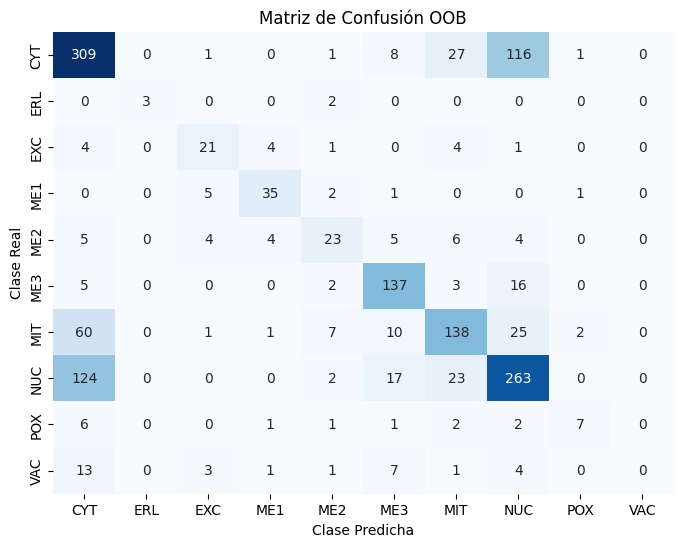

In [41]:
# Visualizar la matriz de confusión usando un heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión OOB')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

Las clases que mejor reconoce el bosque son **ME3** (error 0.16) y **ME1** (error 0.20), que son proteínas de membrana con señales bastante marcadas en alm, mcg y gvh.

La mayor parte de los errores está entre **CYT** y **NUC**: 116 proteínas citosólicas se predicen como nucleares y 124 nucleares como citosólicas. También hay 60 proteínas MIT que se predicen como CYT. Estas tres clases son las más grandes y, como se vio en el PCA, están muy mezcladas.

Las clases chicas son las que peor salen: **VAC** tiene error 1.0 (ninguna de las 30 proteínas se clasifica bien, 13 se predicen como CYT), **POX** tiene error 0.65 y **ME2** 0.55. Con tan pocos datos y tan mezclados con las clases grandes, el modelo tiende a mandarlos a la clase mayoritaria. Un caso interesante es **ERL**: con solo 5 proteínas acierta 3, porque las 5 tienen la señal HDEL (erl = 1).

**Ordenar las características por importancia**

In [42]:
# Importancia de las características
feature_importance = rf_model.feature_importances_

# Ordenar las características por importancia en orden descendente
sorted_idx = np.argsort(feature_importance)[::-1]
sorted_feature_importance = feature_importance[sorted_idx]
sorted_feature_names = np.array(feature_names)[sorted_idx]

print('Variables más importantes ordenadas:')
for name, imp in zip(sorted_feature_names, sorted_feature_importance):
    print(f'{name}: {imp:.4f}')

Variables más importantes ordenadas:
alm: 0.2321
mit: 0.1838
mcg: 0.1783
gvh: 0.1648
vac: 0.1166
nuc: 0.1086
pox: 0.0103
erl: 0.0055


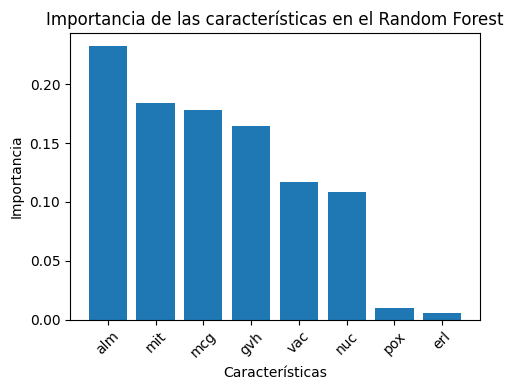

In [43]:
# Crear el gráfico de barras
plt.figure(figsize=(5, 4))
plt.bar(range(len(sorted_feature_importance)), sorted_feature_importance, align='center')
plt.xticks(range(len(sorted_feature_names)), sorted_feature_names, rotation=45)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Importancia de las características en el Random Forest')
plt.tight_layout()
plt.show()

Las variables más importantes para el Random Forest son **alm** (0.2321), **mit** (0.1838), **mcg** (0.1783) y **gvh** (0.1648), seguidas por vac (0.1166) y nuc (0.1086). **pox** (0.0103) y **erl** (0.0055) casi no aportan, porque son prácticamente constantes y solo sirven para separar las pocas proteínas POX y ERL.

Llama la atención que la feature que más pesa en PC1 (mcg) no es la más importante para clasificar. Esto pasa porque PCA busca las direcciones de mayor varianza sin mirar las clases, mientras que el Random Forest elige las variables que mejor separan las clases. alm (regiones de membrana) es clave para separar las tres clases de membrana (ME1, ME2, ME3) del resto.

**¿Qué ventajas tiene la evaluación OOB? ¿En qué se diferencia de evaluar el modelo con un conjunto de test independiente?**

Ventajas de la evaluación OOB:

- No hace falta separar un conjunto de test: se entrena con todos los datos y aun así se obtiene una estimación del error sobre datos no vistos. Esto sirve mucho cuando hay clases con pocos datos, como ERL (5) o POX (20), porque no se pierde ninguno en el entrenamiento.
- Sale "gratis" del propio entrenamiento, sin tener que reentrenar el modelo.
- Es más estable que un único corte train/test, porque cada dato se evalúa con muchos árboles (unos 370 de los 1000 en promedio) y no depende de cómo cayó una partición al azar.

Diferencia con un test independiente: en la evaluación OOB cada dato se predice con un subconjunto distinto de árboles que no lo usaron, mientras que con un test independiente se separa una parte fija de los datos, que el modelo nunca ve, y se evalúa el bosque completo sobre ella. El test independiente es la evaluación más "limpia" para reportar el resultado final, pero reduce los datos de entrenamiento y el resultado puede cambiar según cómo se haga la partición.

### **Árboles de decisión**

In [44]:
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

**Dividir los datos en conjuntos de entrenamiento y prueba**

In [45]:
# dividir los datos en conjuntos de entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [46]:
# Obtener las frecuencias de clases en el conjunto total de entrenamiento
clases_train = pd.Series(label_encoder.inverse_transform(y_train)).value_counts()
print(clases_train)
# Calcular el total de frecuencias
total_frecuencias = clases_train.sum()
print(f'Total {total_frecuencias}')

CYT    323
NUC    301
MIT    167
ME3    118
ME2     39
ME1     25
EXC     24
VAC     22
POX     15
ERL      4
Name: count, dtype: int64
Total 1038


In [47]:
# Obtener las frecuencias de clases en el conjunto total de test
clases_test = pd.Series(label_encoder.inverse_transform(y_test)).value_counts()
print(clases_test)
# Calcular el total de frecuencias
total_frecuencias = clases_test.sum()
print(f'Total {total_frecuencias}')

CYT    140
NUC    128
MIT     77
ME3     45
ME1     19
ME2     12
EXC     11
VAC      8
POX      5
ERL      1
Name: count, dtype: int64
Total 446


**Definir y entrenar un modelo de Árbol de decisión**

In [48]:
# definir y entrenar el modelo
clf = DecisionTreeClassifier(criterion="entropy", min_impurity_decrease=0.03, random_state=0, min_samples_leaf=5)
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', min_impurity_decrease=0.03,
                       min_samples_leaf=5, random_state=0)

In [49]:
# predecir las etiquetas para los datos de prueba y calcular la precisión del modelo
y_pred = clf.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)

**Precisión del modelo**

In [50]:
# imprimir la precisión del modelo
print("Precisión del modelo: {:.2f}".format(accuracy))

Precisión del modelo: 0.56


**Profundidad del árbol y número de hojas**

In [51]:
# Imprimir información sobre el árbol
print(f'Profundidad del árbol: {clf.get_depth()}')
print(f'Número de hojas: {clf.get_n_leaves()}')

Profundidad del árbol: 5
Número de hojas: 9


- **Precisión del modelo:** 0.56 (sobre el conjunto de prueba de 446 proteínas)
- **Profundidad del árbol:** 5
- **Número de hojas:** 9

Con 9 hojas el árbol no puede asignar las 10 clases. De hecho, solo predice 7 clases distintas (CYT, EXC, ME2, ME3, MIT, NUC y POX) y nunca predice ERL, ME1 ni VAC. Es un árbol chico por el parámetro min_impurity_decrease=0.03, que corta las divisiones que mejoran poco la entropía.

**Imprimir las características más importantes**

In [52]:
# Imprimir las características más importantes ordenadas
importances = clf.feature_importances_
sorted_indices = np.argsort(importances)[::-1] # Ordena los índices en orden descendente

print('Variables más importantes ordenadas:')
for idx in sorted_indices:
    nombre_feature = feature_names[idx]
    importance = importances[idx]
    print(f'{nombre_feature}: {importance:.4f}')

Variables más importantes ordenadas:
alm: 0.4216
mcg: 0.2822
mit: 0.1266
gvh: 0.0712
nuc: 0.0639
pox: 0.0344
erl: 0.0000
vac: 0.0000


**Las características más importantes, ¿coinciden con lo observado en Random forest?**

Coinciden en buena parte. Las tres variables más importantes son las mismas en los dos modelos, aunque en distinto orden:

| Posición | Random Forest | Árbol de decisión |
|---|---|---|
| 1 | alm (0.2321) | alm (0.4216) |
| 2 | mit (0.1838) | mcg (0.2822) |
| 3 | mcg (0.1783) | mit (0.1266) |
| 4 | gvh (0.1648) | gvh (0.0712) |

En los dos casos **alm** es la más importante (en el árbol es justamente la variable del nodo raíz) y **erl** no aporta nada. La diferencia es que el árbol concentra la importancia en pocas variables y deja otras en cero (vac y erl), mientras que el Random Forest la reparte entre todas, porque promedia 1000 árboles que en cada división eligen entre subconjuntos al azar de las variables. Por ejemplo, vac es la quinta variable en el Random Forest (0.1166) pero en el árbol tiene importancia 0.

**Realizar un plot del árbol entrenado y guardarlo en PDF**

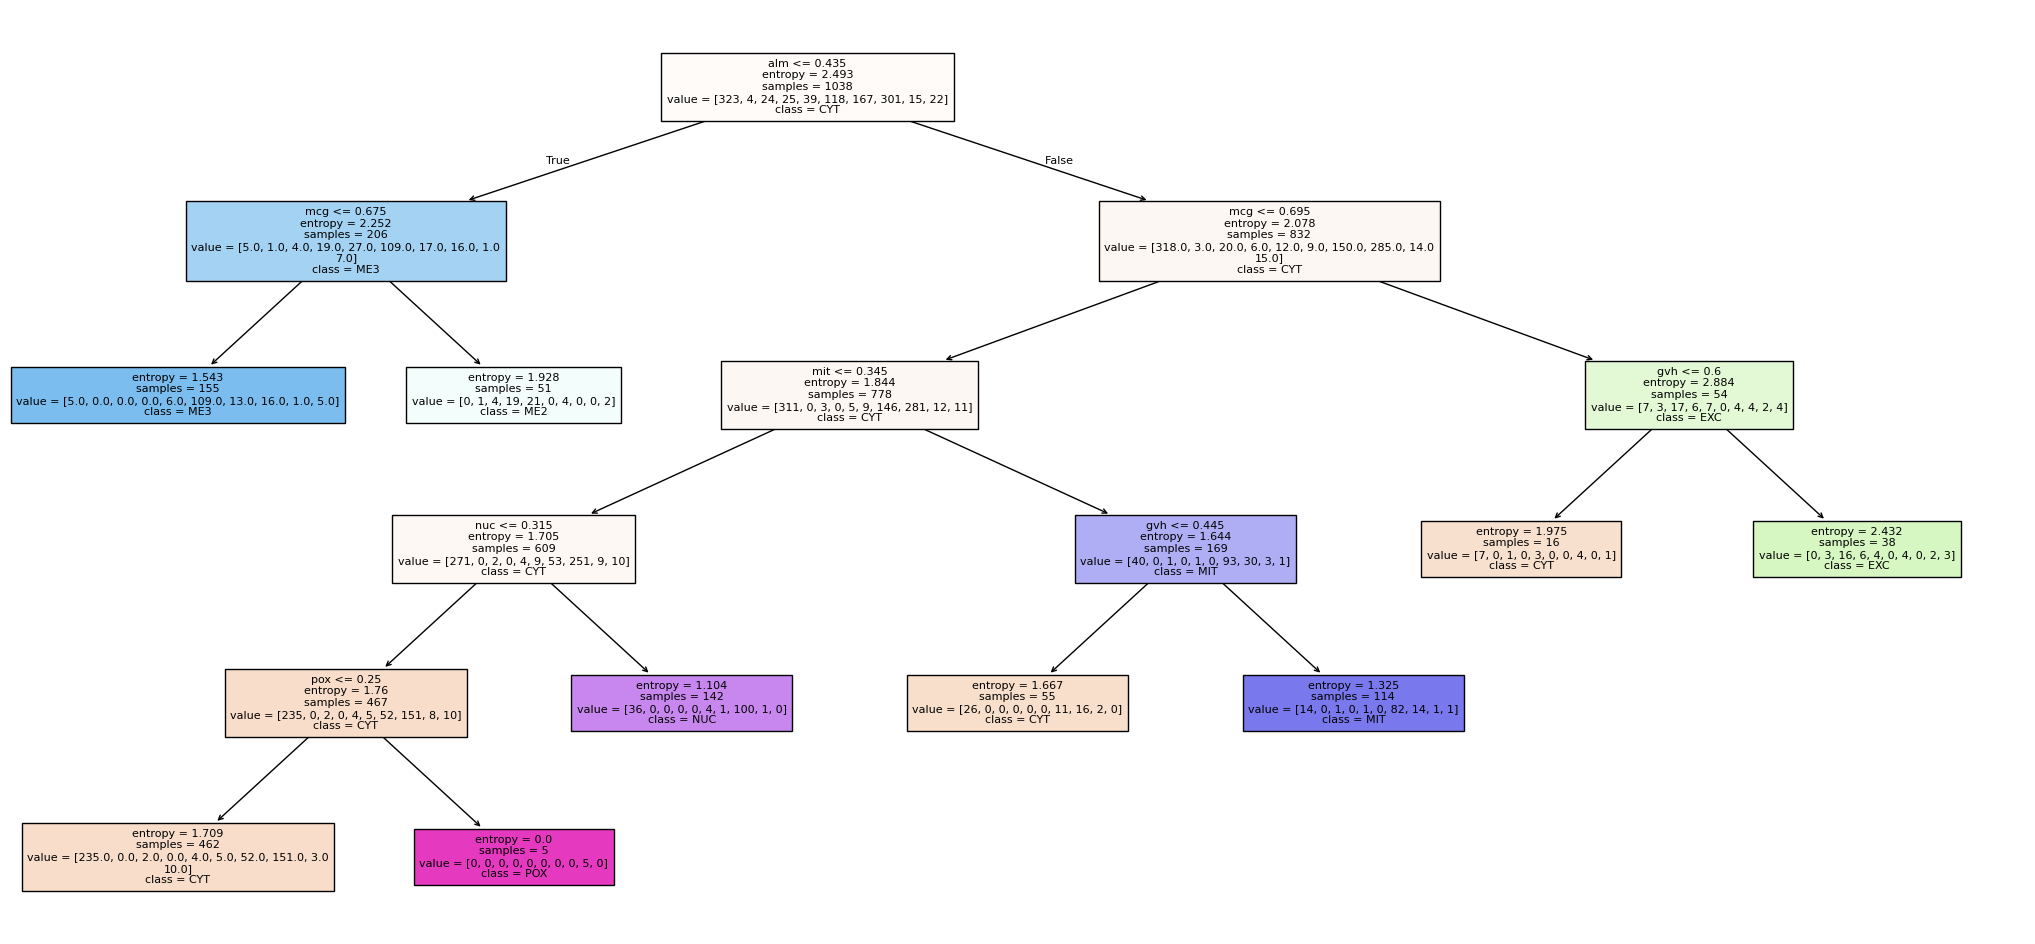

In [53]:
plt.figure(figsize=(26, 12))
plot_tree(clf, filled=True, feature_names=feature_names,
          class_names=[str(cls) for cls in label_encoder.inverse_transform(clf.classes_)],
          fontsize=8)
plt.savefig('decision_tree.pdf', format='pdf')  # Guarda el árbol en formato PDF
plt.show()  # Muestra el árbol en pantalla

### **Optativo: SVM y Deep Learning**

Para SVM y la red neuronal se usan los datos normalizados con MinMaxScaler y se separan en entrenamiento, validación y prueba, igual que en las prácticas. El conjunto de validación se usa para elegir el valor de C (en SVM) y para seguir el entrenamiento (en la red).

In [54]:
# Separar datos para entrenamiento y test
X_train, X_test, Y_train, Y_test = train_test_split(yeast_normalized, y, train_size=0.8, test_size=0.2, random_state=42)

# Subdividir el conjunto de entrenamiento en train y val
X_train, X_val, Y_train, Y_val = train_test_split(X_train, Y_train, train_size=0.8, test_size=0.2, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de validación:", len(X_val))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 949
Tamaño del conjunto de validación: 238
Tamaño del conjunto de prueba: 297


**Máquinas de vectores soporte (SVM)**

In [55]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Valores de C a evaluar
valores_C = np.logspace(-5, 3, num=9)
valores_C

array([1.e-05, 1.e-04, 1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02,
       1.e+03])

En las prácticas se probó C hasta 10^5, pero con este dataset los valores de C mayores a 1000 tardan muchísimo en entrenar (con kernel polinomial, C = 10^4 tardó más de un minuto y C = 10^5 no terminó en 10 minutos) y además la precisión en validación ya empieza a bajar desde C = 10^4 con kernel radial. Por eso se dejó el rango entre 10^-5 y 10^3.

Con kernel radial:

Mejor valor de C: 100.0
Precisión máxima: 0.6134453781512605
Error mínimo en validación: 38.66%


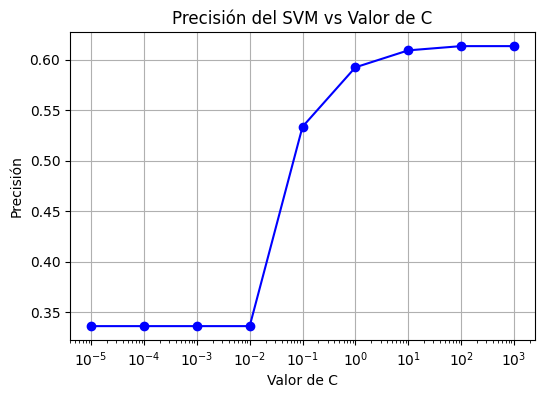


Resultados en el conjunto de prueba:
Precisión en test: 0.5959595959595959
Error en test: 40.4%

Matriz de Confusión:
     CYT  ERL  EXC  ME1  ME2  ME3  MIT  NUC  POX  VAC
CYT   62    0    0    0    0    1    5   27    0    1
ERL    0    0    0    0    0    0    0    0    0    0
EXC    1    0    4    0    0    0    3    0    0    0
ME1    0    0    2    5    1    0    0    0    0    0
ME2    1    0    0    1    3    0    1    0    0    0
ME3    0    0    0    0    1   28    0    4    0    1
MIT   14    0    0    0    2    2   29    5    0    0
NUC   33    0    1    0    1    3    3   44    0    0
POX    0    0    0    0    0    0    0    0    2    0
VAC    2    0    1    0    0    0    2    1    0    0

Reporte de Clasificación:
              precision    recall  f1-score   support

         CYT       0.55      0.65      0.59        96
         ERL       0.00      0.00      0.00         0
         EXC       0.50      0.50      0.50         8
         ME1       0.83      0.62      0.71

In [56]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='rbf', C=C)
    modelo_svm.fit(X_train, Y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(Y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_rbf = SVC(kernel='rbf', C=mejor_C)
modelo_svm_rbf.fit(X_train, Y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_rbf.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_svm_rbf = accuracy_score(Y_test, predicciones_test)
error_test = 1 - precision_svm_rbf
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_svm_rbf}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión (con las 10 clases, aunque alguna no aparezca en test)
matriz_confusion = pd.DataFrame(confusion_matrix(Y_test, predicciones_test, labels=range(10)),
                                index=label_encoder.classes_, columns=label_encoder.classes_)
reporte_clasificacion = classification_report(Y_test, predicciones_test, labels=range(10),
                                              target_names=label_encoder.classes_, zero_division=0)

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

Con kernel polinomial:

Mejor valor de C: 0.1
Precisión máxima: 0.6050420168067226
Error mínimo en validación: 39.5%


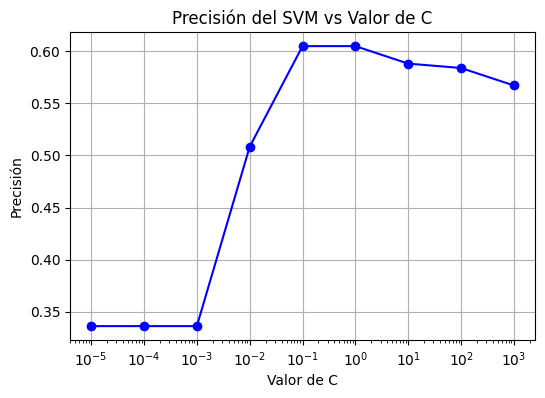


Resultados en el conjunto de prueba:
Precisión en test: 0.6094276094276094
Error en test: 39.06%

Matriz de Confusión:
     CYT  ERL  EXC  ME1  ME2  ME3  MIT  NUC  POX  VAC
CYT   71    0    1    0    0    1    2   21    0    0
ERL    0    0    0    0    0    0    0    0    0    0
EXC    2    0    4    0    0    0    2    0    0    0
ME1    0    0    4    3    1    0    0    0    0    0
ME2    0    0    0    1    3    0    1    1    0    0
ME3    1    0    0    0    0   28    0    5    0    0
MIT   16    0    0    0    2    2   29    3    0    0
NUC   37    0    1    0    1    2    3   41    0    0
POX    0    0    0    0    0    0    0    0    2    0
VAC    2    0    1    1    0    0    1    1    0    0

Reporte de Clasificación:
              precision    recall  f1-score   support

         CYT       0.55      0.74      0.63        96
         ERL       0.00      0.00      0.00         0
         EXC       0.36      0.50      0.42         8
         ME1       0.60      0.38      0.4

In [57]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='poly', C=C)
    modelo_svm.fit(X_train, Y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(X_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(Y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_poly = SVC(kernel='poly', C=mejor_C)
modelo_svm_poly.fit(X_train, Y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_poly.predict(X_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_svm_poly = accuracy_score(Y_test, predicciones_test)
error_test = 1 - precision_svm_poly
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_svm_poly}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión (con las 10 clases, aunque alguna no aparezca en test)
matriz_confusion = pd.DataFrame(confusion_matrix(Y_test, predicciones_test, labels=range(10)),
                                index=label_encoder.classes_, columns=label_encoder.classes_)
reporte_clasificacion = classification_report(Y_test, predicciones_test, labels=range(10),
                                              target_names=label_encoder.classes_, zero_division=0)

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

| Kernel | Mejor C | Precisión en validación | Precisión en test |
|---|---|---|---|
| Radial | 100 | 0.6134 | 0.5960 |
| Polinomial | 0.1 | 0.6050 | 0.6094 |

Los dos kernels dan resultados parecidos, alrededor del 60%. Igual que con el Random Forest, las clases que mejor se reconocen son ME3 y POX (esta última con solo 2 casos en test), y la confusión fuerte sigue siendo entre CYT, NUC y MIT. VAC no se reconoce nunca y ERL no aparece en el conjunto de prueba porque tiene solo 5 datos en total.

**Redes neuronales profundas (Deep Learning)**

In [58]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Fijar semilla para que los resultados se puedan repetir
tf.keras.utils.set_random_seed(42)

# Definir la red neuronal
model = models.Sequential()
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(10, activation='softmax'))  # 10 clases de localización

In [59]:
# Compilar el modelo
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

In [60]:
# Definir hiperparámetros
epocas = 50
batch_size = 32

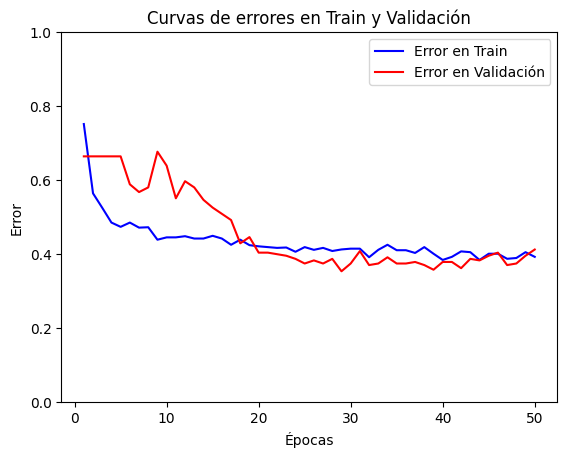

In [61]:
# Entrenar el modelo y almacenar el historial
history = model.fit(X_train, Y_train, epochs=epocas, batch_size=batch_size, validation_data=(X_val, Y_val), verbose=0)

# Graficar error en función de las épocas
# Obtener los valores de accuracy y val_accuracy
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

# Obtener las curvas de error en train y validación
Error_train = [1 - acc for acc in train_accuracy]
Error_val = [1 - acc for acc in val_accuracy]

# Curvas de error en train y validación
epochs = range(1, len(train_accuracy) + 1)
plt.plot(epochs, Error_train, 'b', label='Error en Train')
plt.plot(epochs, Error_val, 'r', label='Error en Validación')
plt.title('Curvas de errores en Train y Validación')
plt.xlabel('Épocas')
plt.ylabel('Error')
plt.ylim([0, 1])
plt.legend()
plt.show()

In [62]:
# Evaluar el modelo con los datos de test
test_loss, precision_dl = model.evaluate(X_test, Y_test, verbose=0)

# Imprimir el resultado
print(f'Pérdida en Test: {test_loss}')
print(f'Precisión en Test: {precision_dl}')

Pérdida en Test: 1.0905312299728394
Precisión en Test: 0.6296296119689941


La red neuronal llega a una **precisión en test de 0.6330**. En la curva de error se ve que el error de entrenamiento y el de validación bajan juntos y se estabilizan alrededor de 0.4, sin que el error de validación vuelva a subir, así que no hay sobreajuste (el Dropout y la BatchNormalization ayudan a eso).

Este valor puede cambiar un poco en cada ejecución por la inicialización aleatoria de los pesos, aunque se fijó una semilla para que sea lo más repetible posible.

**Tabla comparativa**

In [63]:
tabla = pd.DataFrame({
    'Modelo': ['Random Forest', 'Árbol de decisión', 'SVM (kernel radial)', 'SVM (kernel polinomial)', 'Red neuronal'],
    'Evaluación': ['OOB (1484 datos)', 'Test 30% (446 datos)', 'Test 20% (297 datos)', 'Test 20% (297 datos)', 'Test 20% (297 datos)'],
    'Precisión': [rf_model.oob_score_, accuracy, precision_svm_rbf, precision_svm_poly, precision_dl]
})
tabla['Precisión'] = tabla['Precisión'].round(4)
tabla

,Modelo,Evaluación,Precisión
0,Random Forest,OOB (1484 datos),0.6307
1,Árbol de decisión,Test 30% (446 datos),0.5583
2,SVM (kernel radial),Test 20% (297 datos),0.5960
3,SVM (kernel polinomial),Test 20% (297 datos),0.6094
4,Red neuronal,Test 20% (297 datos),0.6296


| Modelo | Evaluación | Precisión |
|---|---|---|
| Random Forest | OOB (1484 datos) | 0.6307 |
| Árbol de decisión | Test 30% (446 datos) | 0.5583 |
| SVM (kernel radial) | Test 20% (297 datos) | 0.5960 |
| SVM (kernel polinomial) | Test 20% (297 datos) | 0.6094 |
| Red neuronal | Test 20% (297 datos) | 0.6330 |

Los mejores resultados son los de la red neuronal y el Random Forest, con un 63%. El árbol de decisión es el más bajo, lo cual es esperable porque es un único árbol chico, mientras que el Random Forest combina 1000 árboles. Hay que tener en cuenta que no todos los modelos se evaluaron de la misma forma (OOB, test del 30% y test del 20%), así que las diferencias de 2 o 3 puntos entre ellos no son concluyentes. Todos superan el 55% del trabajo original de Horton y Nakai.

## **Conclusiones**

- El dataset Yeast tiene 1484 proteínas, 8 features numéricos y 10 clases muy desbalanceadas (CYT y NUC juntan más del 60% de los datos y ERL tiene solo 5). No tiene valores faltantes.
- Con PCA, PC1 + PC2 explican solo el 50.67% de la varianza. PC1 está dominado por mcg y gvh (señales de secreción) y PC2 por mit (señal mitocondrial). En 2D las clases se superponen mucho, lo que ya anticipa que la clasificación va a ser difícil.
- Todos los modelos quedan entre 56% y 63% de precisión. El Random Forest (OOB 0.6307) y la red neuronal (0.6330) son los mejores, y el árbol de decisión el más bajo (0.56).
- Las variables más importantes para clasificar son alm, mit, mcg y gvh, tanto en el Random Forest como en el árbol de decisión. erl y pox casi no aportan porque son prácticamente constantes.
- El principal problema es la confusión entre CYT, NUC y MIT, y el desbalance: las clases chicas (VAC, POX, ERL) casi no se reconocen. Para mejorar se podría probar balancear las clases (por ejemplo con class_weight='balanced') o sumar más información de la secuencia de las proteínas.